In [39]:
import hashlib
import json
import math
import re
import textwrap
import unicodedata
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

RNG = np.random.default_rng(20260813)   # fixed seed: every permutation/bootstrap is reproducible

# ---------------------------------------------------------------- palette
# Validated categorical palette. Slots are assigned in this order and never cycled;
# a chart needing more than 8 identities folds the tail into "Other" instead.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
          "#e87ba4", "#008300", "#4a3aa7", "#e34948"]

SURFACE   = "#fcfcfb"   # chart surface, painted explicitly
INK       = "#0b0b0b"   # primary ink
INK_2     = "#52514e"   # secondary ink
MUTED     = "#898781"   # axis labels, annotations
GRID      = "#e1e0d9"   # hairline gridlines
AXIS      = "#c3c2b7"   # baseline
ZERO_GREY = "#d8d7d1"   # bars for categories with zero observations

# Sequential (magnitude) and diverging (polarity) ramps, built from the same blue ramp.
BLUES = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
         "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ  = LinearSegmentedColormap.from_list("seq_blue", BLUES)
DIV  = LinearSegmentedColormap.from_list("div_blue_red", ["#0d366b", "#3987e5", "#f0efec",
                                                          "#e34948", "#8f1f1f"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE,   "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,  "figure.dpi": 110,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 9.5,
    "text.color": INK,             "axes.labelcolor": INK_2,
    "xtick.color": MUTED,          "ytick.color": MUTED,
    "xtick.labelsize": 8.5,        "ytick.labelsize": 8.5,
    "axes.edgecolor": AXIS,        "axes.linewidth": 0.8,
    "axes.spines.top": False,      "axes.spines.right": False,
    "axes.grid": True,             "grid.color": GRID,
    "grid.linewidth": 0.7,         "axes.axisbelow": True,
    "legend.frameon": False,       "legend.fontsize": 8.5,
    "axes.titlesize": 11,          "axes.titleweight": "semibold",
    "axes.titlelocation": "left",  "axes.titlepad": 14,
})

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 120)

print("style loaded | palette:", " ".join(SERIES))

style loaded | palette: #2a78d6 #eb6834 #1baf7a #eda100 #e87ba4 #008300 #4a3aa7 #e34948


In [40]:
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import pandas as pd

# Works whether the notebook is run from src/ or from the repository root.
REPO = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()

RUN_PATH = REPO / "runs" / "predictions_chr_sample25.jsonl"
CORPUS_PATH = REPO / "data" / "corpus_chr.jsonl"
#XLSX_PATH = REPO / "runs" / "gide_opus5_relations.xlsx"
IMGS_PATH = REPO / "imgs"

CLOSED_FIELDS = [
    "relation_type", "structure",
    "status", "reciprocity", "exclusivity", "adultery",
    "explicitness", "explicitness_in_plot",
    "centrality", "framing", "outcome",
    "confidence",
]
REL_COLUMNS = ["novel_id","orientation", "model", "relation_id", "characters"] + CLOSED_FIELDS + ["n_evidence", "comment"]
EV_COLUMNS = ["novel_id", "relation_id", "evidence_index", "quote", "locator", "description"]

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)

In [41]:
records = [
    json.loads(line)
    for line in RUN_PATH.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
print(f"{len(records)} record(s)\n")

100 record(s)



In [42]:
def relation_rows(records):
    for r in records:
        annotation = r.get("annotation") or {}
        for rel in annotation.get("relations") or []:
            row = {
                "novel_id": r.get("novel_id"),
                'orientation': r.get("orientation"),
                "model": r.get("model"),
                "relation_id": rel.get("relation_id"),
                "characters": " | ".join(str(c) for c in rel.get("characters") or []),
                "n_evidence": len(rel.get("evidence") or []),
                "comment": rel.get("comment"),
            }
            row.update({f: rel.get(f) for f in CLOSED_FIELDS})
            yield row


relations = pd.DataFrame(list(relation_rows(records)), columns=REL_COLUMNS)
relations

,novel_id,orientation,model,relation_id,characters,relation_type,structure,status,reciprocity,exclusivity,adultery,explicitness,explicitness_in_plot,centrality,framing,outcome,confidence,n_evidence,comment
0,alanic_roses,hetero,anthropic/claude-opus-5,R1,Estelle Gerfaux | Vincent Marcenat,female_male,dyadic,married,reciprocal,exclusive,loyal,explicit,explicit,main,positive,stable_or_open,high,7,"Relation centrale. Le bond initial est un mariage de dévouement, p..."
1,alanic_roses,hetero,anthropic/claude-opus-5,R2,Estelle Gerfaux | Renaud Jonchère,female_male,dyadic,engaged,asymmetrical,exclusive,adultery_one,explicit,hidden_except,main,neutral_ambivalent,separation_erasure,high,7,"Fiançailles secrètes, non officialisées mais nommées comme telles ..."
2,alanic_roses,hetero,anthropic/claude-opus-5,R3,Adrien Gerfaux | Monique Françon,female_male,dyadic,married,reciprocal,exclusive,loyal,explicit,explicit,secondary,positive,stable_or_open,high,4,"Sous-intrigue conjugale entièrement valorisée, contrepoint heureux..."
3,alanic_roses,hetero,anthropic/claude-opus-5,R4,Vincent Marcenat | Odette de Tintaniac (Mme Marcenat),female_male,dyadic,married,asymmetrical,exclusive,unclear,explicit,explicit,secondary,moralized_pathologized,fatal_ending,high,4,Mariage malheureux servant de préhistoire au roman. La règle affic...
4,alanic_roses,hetero,anthropic/claude-opus-5,R5,Renaud Jonchère | Mme de Leucate,female_male,dyadic,physical_relationship,unclear,adultery,external_adultery,rumor,explicit,secondary,eroticized_exoticized,separation_erasure,medium,3,"Relation connue seulement par lettre et chroniques (« sirène », « ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
897,zuylen_chemin,lesbiennes,anthropic/claude-opus-5,R10,Giovanna Montenari | le fils aîné du roi de France,female_male,dyadic,romantic_relationship,reciprocal,adultery,external_adultery,explicit,explicit_except,episode,decadent_sublime,fatal_ending,high,3,Explicit adulterous relation (exclusivity = adultery with adultery...
898,zuylen_chemin,lesbiennes,anthropic/claude-opus-5,R11,Angiola Montenari | le prétendant qui répudia Donna Fiamma,female_male,triangular,seduction,one_sided,uncommitted,none,explicit,explicit,episode,decadent_sublime,fatal_ending,medium,3,"Coded as triangular because the repudiated Donna Fiamma, of a 'lig..."
899,zuylen_chemin,lesbiennes,anthropic/claude-opus-5,R12,Andriana Montenari | l'auteur inconnu des lettres d'amour | Don Fe...,female_male,triangular,romantic_relationship,unclear,adultery,external_adultery,explicit,hidden,episode,decadent_sublime,fatal_ending,low,2,"Only two sentences of ancestral legend, but they name love letters..."
900,zuylen_chemin,lesbiennes,anthropic/claude-opus-5,R13,Dante Alighieri | Donna Béatrice,female_male,dyadic,romantic_relationship,one_sided,uncommitted,none,explicit,explicit,episode,decadent_sublime,separation_erasure,medium,2,"An embedded literary legend, retained because it is the explicit m..."


In [43]:
SCHEMA_PATH   = REPO / "schemas" / "novel_annotation_v2.schema.json"
METADATA_PATH = REPO / "data" / "corpus_chr_metadata.csv"

schema = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
_relprops = (schema["properties"]["relations"]["items"]["properties"])

# LEVELS[field] -> labels in codebook order ; GLOSS[field][label] -> the codebook definition
LEVELS, GLOSS = {}, {}
for _f in CLOSED_FIELDS:
    LEVELS[_f] = list(_relprops[_f]["enum"])
    _desc = _relprops[_f].get("description", "")
    GLOSS[_f] = {}
    for _lab in LEVELS[_f]:
        m = re.search(rf"(?:^|[;.]\s*){re.escape(_lab)}\s*[=:—-]\s*(.+?)(?=(?:;\s*\w+\s*[=:])|$)",
                      _desc, flags=re.S)
        GLOSS[_f][_lab] = re.sub(r"\s+", " ", m.group(1)).strip(" .;") if m else ""

FIELD_FAMILIES = {
    "Participants and shape":        ["relation_type", "structure"],
    "Nature and rules of the bond":  ["status", "reciprocity", "exclusivity", "adultery"],
    "Representation and narrative role": ["explicitness", "explicitness_in_plot",
                                          "centrality", "framing", "outcome"],
    "Annotation metadata":           ["confidence"],
}

FAMILY_OF = {f: fam for fam, fs in FIELD_FAMILIES.items() for f in fs}

# Author-orientation groups, as recorded by the corpus directory structure.
ORIENTATION_LABELS = {
    "hetero":      "Heterosexual women authors",
    "lesbiennes":  "Lesbian authors",
    "homosexuels": "Gay men authors",
    "homhet":      "Heterosexual men authors",
}
ORIENTATION_ORDER = ["hetero", "lesbiennes", "homosexuels", "homhet"]

def pretty(label):
    """Machine label -> human label for axes and legends."""
    if label is None or (isinstance(label, float) and math.isnan(label)):
        return "(missing)"
    return str(label).replace("_", " ")

def pretty_field(field):
    return str(field).replace("_", " ")


In [44]:
from scipy.stats import chi2_contingency

OTHERS = ["mixed_gender", "unknown_gender", "queer", "unclear"]   # -> "other"
rel = relations.assign(
    relation_type=relations["relation_type"].astype(str).pipe(
        lambda s: s.where(~s.isin(OTHERS), "other"))
)

dft = rel.groupby("orientation", observed=True)["relation_type"].value_counts().unstack(fill_value=0)
#dft = dft.reindex(columns=[l for l in LEVELS["relation_type"] if l in dft.columns])
dft = dft.reindex(index=[o for o in ORIENTATION_ORDER if o in dft.index])
dft.index = [ORIENTATION_LABELS.get(o, o) for o in dft.index]

chi2, p, dof, exp = chi2_contingency(dft)
print(f"chi2 = {chi2:.1f}   dof = {dof}   p = {p:.3g}   min expected = {exp.min():.1f}")

pct = dft.divide(dft.sum(axis=1), axis=0) * 100
pct.index.name = "author orientation"
pct.columns = [pretty(c) for c in pct.columns]
display(pct.style.format("{:.1f}%").background_gradient(cmap=SEQ, axis=1))

chi2 = 201.8   dof = 9   p = 1.36e-38   min expected = 9.1


,female female,female male,male male,other
author orientation,,,,
Heterosexual women authors,1.1%,92.0%,5.1%,1.7%
Lesbian authors,29.5%,58.6%,2.2%,9.7%
Gay men authors,7.2%,70.1%,17.1%,5.6%
Heterosexual men authors,1.6%,91.2%,4.0%,3.2%


## Outcome by orientation

In [45]:
#OTHERS = ["mixed_gender", "unknown_gender", "queer", "unclear"]   # -> "other"
rel = relations.assign(
    relation_type=relations["relation_type"].astype(str).pipe(
        lambda s: s.where(~s.isin(OTHERS), "other"))
)

dft = rel.groupby("orientation", observed=True)["outcome"].value_counts().unstack(fill_value=0)
#dft = dft.reindex(columns=[l for l in LEVELS["relation_type"] if l in dft.columns])
dft = dft.reindex(index=[o for o in ORIENTATION_ORDER if o in dft.index])
dft.index = [ORIENTATION_LABELS.get(o, o) for o in dft.index]

chi2, p, dof, exp = chi2_contingency(dft)
print(f"chi2 = {chi2:.1f}   dof = {dof}   p = {p:.3g}   min expected = {exp.min():.1f}")

pct = dft.divide(dft.sum(axis=1), axis=0) * 100
pct.index.name = "author orientation"
pct.columns = [pretty(c) for c in pct.columns]
display(pct.style.format("{:.1f}%").background_gradient(cmap=SEQ, axis=1))

chi2 = 66.6   dof = 21   p = 1.23e-06   min expected = 2.7


,fatal ending,illness madness decline,open contested,return to norm,separation erasure,social disgrace,stable or open,unclear
author orientation,,,,,,,,
Heterosexual women authors,28.0%,1.7%,4.6%,9.1%,32.6%,4.0%,19.4%,0.6%
Lesbian authors,17.6%,1.8%,7.5%,4.0%,43.2%,2.6%,20.7%,2.6%
Gay men authors,19.1%,1.6%,8.0%,3.2%,35.9%,5.6%,15.5%,11.2%
Heterosexual men authors,12.9%,1.2%,6.0%,6.4%,31.3%,6.8%,25.7%,9.6%


## Framing by orientation

In [46]:
#OTHERS = ["mixed_gender", "unknown_gender", "queer", "unclear"]   # -> "other"
rel = relations.assign(
    relation_type=relations["relation_type"].astype(str).pipe(
        lambda s: s.where(~s.isin(OTHERS), "other"))
)

dft = rel.groupby("orientation", observed=True)["framing"].value_counts().unstack(fill_value=0)
#dft = dft.reindex(columns=[l for l in LEVELS["relation_type"] if l in dft.columns])
dft = dft.reindex(index=[o for o in ORIENTATION_ORDER if o in dft.index])
dft.index = [ORIENTATION_LABELS.get(o, o) for o in dft.index]

chi2, p, dof, exp = chi2_contingency(dft)
print(f"chi2 = {chi2:.1f}   dof = {dof}   p = {p:.3g}   min expected = {exp.min():.1f}")

pct = dft.divide(dft.sum(axis=1), axis=0) * 100
pct.index.name = "author orientation"
pct.columns = [pretty(c) for c in pct.columns]
display(pct.style.format("{:.1f}%").background_gradient(cmap=SEQ, axis=1))

chi2 = 135.7   dof = 21   p = 8.69e-19   min expected = 6.6


,comic caricatural,decadent sublime,eroticized exoticized,moralized pathologized,neutral ambivalent,positive,predatory or corrupting,redemptive spiritualized
author orientation,,,,,,,,
Heterosexual women authors,10.3%,18.9%,3.4%,12.6%,20.0%,18.3%,11.4%,5.1%
Lesbian authors,8.4%,26.4%,7.0%,7.9%,24.7%,11.5%,7.5%,6.6%
Gay men authors,7.6%,19.5%,12.4%,15.1%,26.7%,7.2%,8.4%,3.2%
Heterosexual men authors,31.3%,9.6%,10.4%,11.2%,24.9%,5.2%,6.4%,0.8%


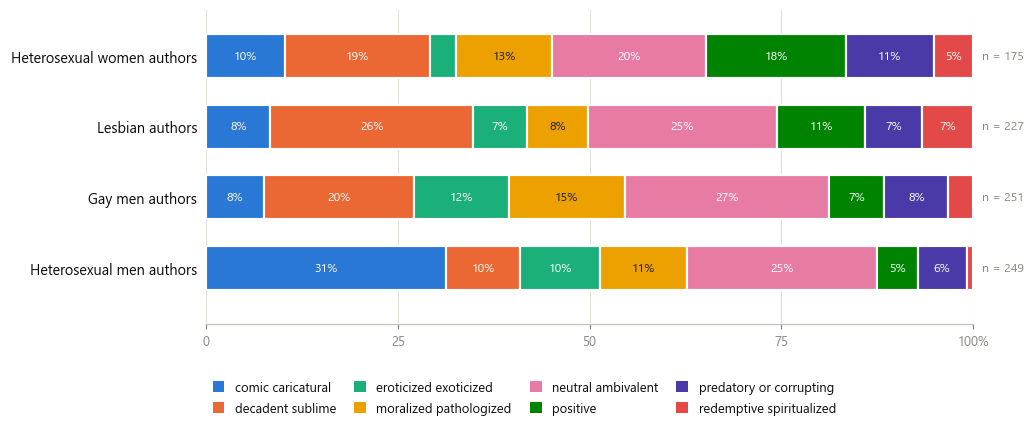

In [47]:
WHITE = "#ffffff"

def _ink_on(hexcolor):
    r, g, b = (int(hexcolor[i:i+2], 16) / 255 for i in (1, 3, 5))
    return "#ffffff" if (0.2126*r + 0.7152*g + 0.0722*b) < 0.6 else "#1a1a1a"


def plot_row_profiles(pct, counts=None, title=None, subtitle=None,
                      max_cats=8, min_label=5.0, figsize=(9.5, 4.0)):
    """100% stacked horizontal bars: one bar per row of `pct`, segments = columns."""
    d = pct.copy()
    if d.shape[1] > max_cats:                       # fold the rarest levels into "other"
        small = d.mean(axis=0).sort_values().index[: d.shape[1] - max_cats + 1]
        keep = [c for c in d.columns if c not in set(small)]
        d = d[keep].copy()
        d["other"] = pct[list(small)].sum(axis=1)

    cats = list(d.columns)
    colors = {c: SERIES[i % len(SERIES)] for i, c in enumerate(cats)}
    if "other" in colors:
        colors["other"] = "#b9b8b1"

    fig, ax = plt.subplots(figsize=figsize, facecolor=WHITE)
    ax.set_facecolor(WHITE)
    y = np.arange(len(d))[::-1]
    left = np.zeros(len(d))
    for c in cats:
        w = d[c].to_numpy(dtype=float)
        ax.barh(y, w, left=left, height=0.62, color=colors[c],
                edgecolor=WHITE, linewidth=1.4, label=c, zorder=3)
        for yi, wi, li in zip(y, w, left):
            if wi >= min_label:
                ax.text(li + wi/2, yi, f"{wi:.0f}%", ha="center", va="center",
                        fontsize=8, color=_ink_on(colors[c]), zorder=4)
        left += w

    ax.set_yticks(y, list(d.index), fontsize=9.5, color=INK)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100], ["0", "25", "50", "75", "100%"])
    ax.xaxis.grid(True, color=GRID, linewidth=0.7)
    ax.yaxis.grid(False)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0, pad=6)
    ax.set_ylim(-0.8, len(d) - 0.35)

    if counts is not None:
        for yi, n in zip(y, np.asarray(counts, dtype=int)):
            ax.text(101.2, yi, f"n = {n}", va="center", ha="left", fontsize=8, color=MUTED)

    if title:
        ax.set_title(title, color=INK, pad=32)
    if subtitle:
        ax.text(0, 1.025, subtitle, transform=ax.transAxes,
                fontsize=8.5, color=MUTED, va="bottom")

    handles = [Patch(facecolor=colors[c], label=c) for c in cats]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0, -0.16),
              ncol=min(4, len(cats)), handlelength=0.9, handleheight=0.9,
              columnspacing=1.4, labelspacing=0.6, borderpad=0)
    fig.tight_layout()
    return fig


fig = plot_row_profiles(
    pct, counts=dft.sum(axis=1),
)
fig.savefig(IMGS_PATH / "fig_framing_by_orientation.png", dpi=300,
            bbox_inches="tight", facecolor="white")

## Explicitness by orientation and relation type

In [61]:
OTHERS = ["mixed_gender", "unknown_gender", "queer", "unclear"]   # -> "other"
rel = relations.copy()

ORIENTATION_LABELS = {
    "hetero":      "Heterosexual women authors",
    "lesbiennes":  "Lesbian authors",
    "homosexuels": "Gay men authors",
    "homhet":      "Heterosexual men authors",
}
RELATION_TYPE_LABELS = {"mixed_gender": "Gender-NC","unknown_gender": "Gender-NC","queer": "Gender-NC","unclear": "Gender-NC"}

rel.replace({"orientation": ORIENTATION_LABELS, "relation_type": RELATION_TYPE_LABELS}, inplace=True)

dft = rel.groupby(["orientation","relation_type"], observed=True)["explicitness"].value_counts().unstack(fill_value=0)
dft

explicitness                              coded  explicit  rumor  weak_inference
orientation                relation_type                                        
Gay men authors            Gender-NC          3         9      2               0
                           female_female     11         6      0               1
                           female_male       22       140     11               3
                           male_male         20        19      1               3
Heterosexual men authors   Gender-NC          2         5      1               0
                           female_female      2         0      0               2
                           female_male       31       175     20               1
                           male_male          5         0      1               4
Heterosexual women authors Gender-NC          2         0      1               0
                           female_female      2         0      0               0
                           female_male       25       131      4               1
                           male_male          7         0      0               2
Lesbian authors            Gender-NC          7        14      1               0
                           female_female     32        30      1               4
                           female_male       21       105      7               0
                           male_male          1         4      0               0

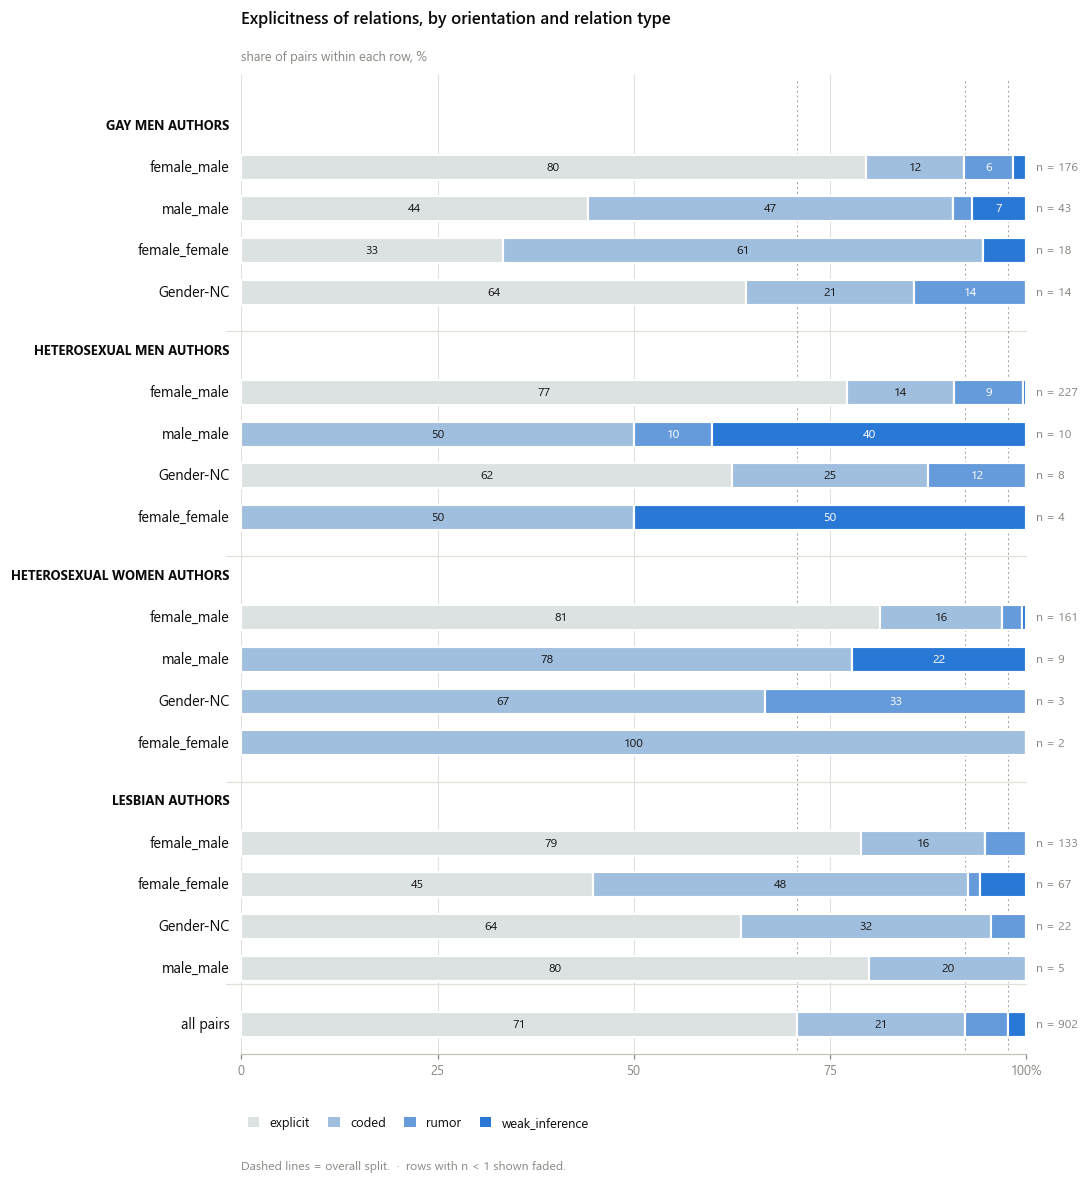

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap, to_hex

WHITE  = "#ffffff"
INK    = globals().get("INK",    "#1a1a1a")
MUTED  = globals().get("MUTED",  "#8b8880")
GRID   = globals().get("GRID",   "#e7e5df")
SERIES = globals().get("SERIES", ["#2b6a70", "#c8a35a", "#a34e3b", "#6b7f9e"])


def _ink_on(hexcolor):
    r, g, b = (int(hexcolor[i:i+2], 16) / 255 for i in (1, 3, 5))
    return "#ffffff" if (0.2126*r + 0.7152*g + 0.0722*b) < 0.6 else "#1a1a1a"


def ordinal_ramp(n, lo="#efece3", hi=None):
    """Light -> saturated ramp: explicitness is ordinal, so don't use categorical hues."""
    cmap = LinearSegmentedColormap.from_list("ord", [lo, hi or SERIES[0]])
    return [to_hex(cmap(x)) for x in np.linspace(0.10, 1.0, n)]


def plot_grouped_profiles(dft, level_order=None, group_order=None, sort_rows="last",
                          min_n=10, min_label=6.0, add_total=True, colors=None,
                          title=None, subtitle=None, note=None, figsize=None):
    """
    100% stacked bars for a 2-level cross-tab.
      rows    = (group, subgroup) from a MultiIndex   -> e.g. (orientation, relation_type)
      segments= columns, assumed ordinal              -> e.g. explicitness
    Dashed verticals mark the overall split, so deviation per row is readable at a glance.
    """
    d = dft.copy()
    if level_order:                                     # keep the ordinal order of columns
        d = d[[c for c in level_order if c in d.columns]
              + [c for c in d.columns if c not in level_order]]
    cats = list(d.columns)

    n_all = d.sum(axis=1)
    d, n_all = d.loc[n_all > 0], n_all.loc[n_all > 0]
    pct = d.div(n_all, axis=0) * 100

    groups = list(dict.fromkeys(pct.index.get_level_values(0)))
    if group_order:
        groups = ([g for g in group_order if g in groups]
                  + [g for g in groups if g not in group_order])

    # ---------------------------------------------------------------- layout --
    ROW, GAP, HEAD = 1.0, 0.45, 0.95
    Y, LAB, NN, OK, VALS, heads, rules = [], [], [], [], [], [], []
    cur = 0.0
    for gi, g in enumerate(groups):
        sub, nsub = pct.loc[g], n_all.loc[g]
        if sort_rows == "last":
            sub = sub.sort_values(cats[-1], ascending=False)
        elif sort_rows == "n":
            sub = sub.loc[nsub.sort_values(ascending=False).index]
        if gi:
            rules.append(cur - HEAD / 2)
        cur -= HEAD
        heads.append((str(g), cur))
        for r in sub.index:
            cur -= ROW
            Y.append(cur); LAB.append(str(r)); NN.append(int(nsub[r]))
            OK.append(int(nsub[r]) >= min_n); VALS.append(sub.loc[r].to_numpy(float))
        cur -= GAP

    tot = d.sum(axis=0)
    tot_pct = (tot / tot.sum() * 100).to_numpy(float)
    if add_total:
        rules.append(cur + GAP / 2 - 0.15)
        cur -= ROW * 0.9
        Y.append(cur); LAB.append("all pairs"); NN.append(int(tot.sum()))
        OK.append(True); VALS.append(tot_pct)

    M = np.vstack(VALS)
    Y = np.asarray(Y, float)
    colors = colors or dict(zip(cats, ordinal_ramp(len(cats))))
    figsize = figsize or (10, 0.40 * len(Y) + 0.42 * len(groups) + 2.3)

    # ----------------------------------------------------------------- draw ---
    fig, ax = plt.subplots(figsize=figsize, facecolor=WHITE)
    ax.set_facecolor(WHITE)
    trans = ax.get_yaxis_transform()                     # x = axes frac, y = data

    left = np.zeros(len(Y))
    for j, c in enumerate(cats):
        w = M[:, j]
        bars = ax.barh(Y, w, left=left, height=0.60, color=colors[c],
                       edgecolor=WHITE, linewidth=1.4, zorder=3)
        for b, ok in zip(bars, OK):
            if not ok:
                b.set_alpha(0.45)
        for yi, wi, li, ok in zip(Y, w, left, OK):
            if wi >= min_label and ok:
                ax.text(li + wi / 2, yi, f"{wi:.0f}", ha="center", va="center",
                        fontsize=8, color=_ink_on(colors[c]), zorder=4)
        left += w

    for x in np.cumsum(tot_pct)[:-1]:                    # overall reference split
        ax.plot([x, x], [Y.min() - 0.6, 0.15], color=INK, lw=0.7,
                ls=(0, (2, 2.5)), alpha=.35, zorder=2)
    for yr in rules:
        ax.plot([-0.02, 1], [yr, yr], transform=trans, color=GRID,
                lw=0.8, zorder=1, clip_on=False)

    # --------------------------------------------------------------- labels ---
    ax.set_yticks([])
    for yi, lab, ok in zip(Y, LAB, OK):
        ax.text(-0.015, yi, lab + ("" if ok else " ·"), transform=trans,
                ha="right", va="center", fontsize=9.5,
                color=INK if ok else MUTED)
    for g, yh in heads:
        ax.text(-0.015, yh, g.upper(), transform=trans, ha="right", va="center",
                fontsize=8.5, color=INK, fontweight="bold")
    for yi, k, ok in zip(Y, NN, OK):
        ax.text(101.2, yi, f"n = {k}", va="center", ha="left", fontsize=8,
                color=MUTED if ok else "#b9b8b1")

    ax.set_xlim(0, 100)
    ax.set_ylim(Y.min() - 0.7, 0.25)
    ax.set_xticks([0, 25, 50, 75, 100], ["0", "25", "50", "75", "100%"])
    ax.xaxis.grid(True, color=GRID, linewidth=0.7)
    ax.yaxis.grid(False)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)

    if title:
        ax.set_title(title, color=INK, pad=34, loc="left")
    if subtitle:
        ax.text(0, 1.012, subtitle, transform=ax.transAxes, fontsize=8.5,
                color=MUTED, va="bottom")

    off = -0.62 / figsize[1]
    ax.legend(handles=[Patch(facecolor=colors[c], label=str(c)) for c in cats],
              loc="upper left", bbox_to_anchor=(0, off), ncol=min(5, len(cats)),
              handlelength=0.9, handleheight=0.9, columnspacing=1.4,
              labelspacing=0.6, borderpad=0, frameon=False)
    ax.text(0, off - 0.55 / figsize[1],
            note or f"Dashed lines = overall split.  ·  rows with n < {min_n} shown faded.",
            transform=ax.transAxes, fontsize=8, color=MUTED, va="top")

    fig.tight_layout()
    return fig


# ------------------------------------------------------------------- usage ---
LEVEL_ORDER = ["explicit","coded","rumor","weak_inference"]   # <- set to your labels
GROUP_ORDER = ["female_male","female_female","male_male","Gender-NC"]   # <- set

fig = plot_grouped_profiles(
    dft,
    level_order=LEVEL_ORDER,
    group_order=GROUP_ORDER,          # e.g. ["gay", "lesbian", "het", "Gender-NC"]
   sort_rows="n",          # rank relation types by share of the top level
    min_n=1,
    title="Explicitness of relations, by orientation and relation type",
    subtitle="share of pairs within each row, %",
)
# fig.savefig(IMGS_PATH / "fig_explicitness_by_orientation_relation.png", dpi=300,
#             bbox_inches="tight", facecolor="white")

In [59]:
dft

explicitness               coded  explicit  rumor  weak_inference
orientation relation_type                                        
hetero      Gender-NC          2         0      1               0
            female_female      2         0      0               0
            female_male       25       131      4               1
            male_male          7         0      0               2
homhet      Gender-NC          2         5      1               0
            female_female      2         0      0               2
            female_male       31       175     20               1
            male_male          5         0      1               4
homosexuels Gender-NC          3         9      2               0
            female_female     11         6      0               1
            female_male       22       140     11               3
            male_male         20        19      1               3
lesbiennes  Gender-NC          7        14      1               0
            female_female     32        30      1               4
            female_male       21       105      7               0
            male_male          1         4      0               0

In [56]:
rel.explicitness.value_counts()

explicitness
explicit          638
coded             193
rumor              50
weak_inference     21
Name: count, dtype: int64

explicitness               coded  explicit  rumor  weak_inference
orientation relation_type                                        
hetero      Gender-NC          2         0      1               0
            female_female      2         0      0               0
            female_male       25       131      4               1
            male_male          7         0      0               2
homhet      Gender-NC          2         5      1               0
            female_female      2         0      0               2
            female_male       31       175     20               1
            male_male          5         0      1               4
homosexuels Gender-NC          3         9      2               0
            female_female     11         6      0               1
            female_male       22       140     11               3
            male_male         20        19      1               3
lesbiennes  Gender-NC          7        14      1               0
            female_female     32        30      1               4
            female_male       21       105      7               0
            male_male          1         4      0               0